<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/js13/TG13_3_244107020211_NURFINKA_LAILASARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **JS13 - Artificial Neural Network (ANN) dan Evaluasi Classifier**

# **PRAKTIKUM 3**

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

# Model
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100)

# Evaluasi
print("Prediksi:", model.predict(X_test))

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 688ms/step - loss: 0.4293
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - loss: 0.4213
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.4134
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - loss: 0.4055
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.3977
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - loss: 0.3900
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.3823
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.3748
Epoch 9/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.3673
Epoch 10/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - loss: 0.3599
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - loss: 0.3526
Epoch 12/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - loss: 0.3454
Epoch 13/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - loss: 0.3383
Epoch 14/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.3313
Epoch 15/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - loss: 0.3243
Epoch 16/100
1/1 ━━━━━━━━━━━━━

## **Tugas 4:**

* Ubah learning rate.
* Bandingkan hasil loss.

 learning_rate  loss_awal  loss_akhir    test_loss
        0.0001   0.972501    0.880277 1.262960e-07
        0.0010   2.885145    1.542680 7.167357e-03
        0.0100   0.835461    0.004017 2.379717e-02
        0.1000   1.724620    0.000027 3.570931e-06
        1.0000   1.729828    0.000003 7.898818e-05

Learning rate terbaik (loss akhir terendah): 1.0


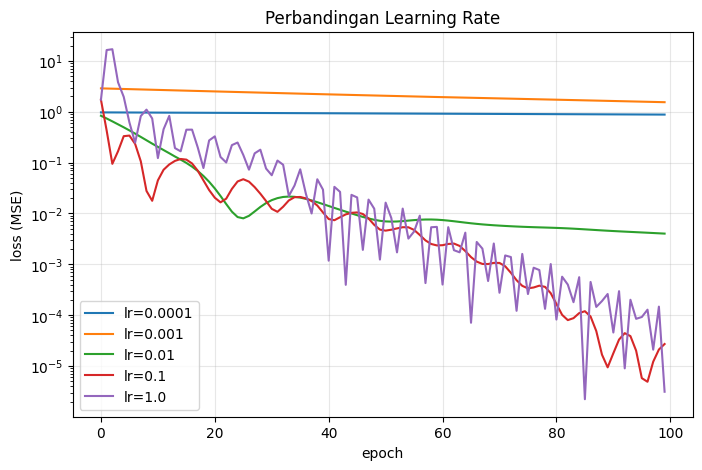

In [11]:
# Tugas 4: ubah learning rate dan bandingkan loss
learning_rates = [0.0001, 0.001, 0.01, 0.1, 1.0]
histories = {}
hasil = []

for lr in learning_rates:
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(1,)),
        tf.keras.layers.Dense(10, activation='relu'),
        tf.keras.layers.Dense(1)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    h = model.fit(X_train, y_train, epochs=100, verbose=0)

    histories[lr] = h.history['loss']
    test_loss = model.evaluate(X_test, y_test, verbose=0)
    hasil.append({
        'learning_rate': lr,
        'loss_awal': h.history['loss'][0],
        'loss_akhir': h.history['loss'][-1],
        'test_loss': test_loss
    })

# Tabel perbandingan
df_hasil = pd.DataFrame(hasil)
print(df_hasil.to_string(index=False))
print("\nLearning rate terbaik (loss akhir terendah):",
      df_hasil.loc[df_hasil['loss_akhir'].idxmin(), 'learning_rate'])

# Grafik perbandingan
plt.figure(figsize=(8,5))
for lr, loss in histories.items():
    plt.plot(loss, label=f'lr={lr}')
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('loss (MSE)')
plt.title('Perbandingan Learning Rate'); plt.legend(); plt.grid(alpha=0.3)
plt.show()

#### Praktikum berikut akan menggunakan data Boston untuk memprediksi harga rumah.

In [3]:
# MLP regresi (Keras)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

In [4]:
# 1. Load
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)
X = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
y = raw_df.values[1::2, 2]

In [5]:
# 2. Preprocess
scaler = StandardScaler(); Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

In [6]:
# 3. Build model
model = Sequential([
Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
Dense(32, activation='relu'),
Dense(1)
])
model.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
# 4. Train
h = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

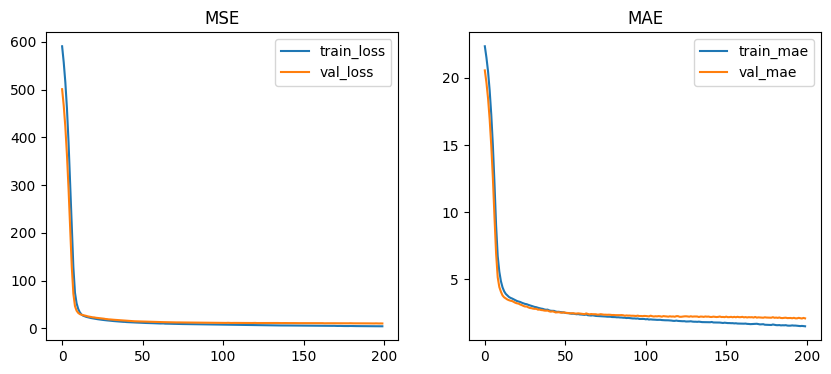

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
RMSE: 3.1757732085226618


In [8]:
# 5. Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(h.history['loss'], label='train_loss'); plt.plot(h.history['val_loss'], label='val_loss'); plt.legend(); plt.title('MSE')
plt.subplot(1,2,2); plt.plot(h.history['mae'], label='train_mae'); plt.plot(h.history['val_mae'], label='val_mae'); plt.legend(); plt.title('MAE')
plt.show()

from sklearn.metrics import mean_squared_error
pred = model.predict(X_val)
print('RMSE:', np.sqrt(mean_squared_error(y_val, pred)))

## **DATASET PBL**

In [12]:
!pip install -q kagglehub[pandas-datasets]

import kagglehub
import os

# Download dataset dan lihat nama file di dalamnya
path = kagglehub.dataset_download("abiyyurasyiq/jakarta-house-price-dataset")
print(os.listdir(path))

100%|██████████| 122k/122k [00:00<00:00, 558kB/s]

Extracting files...
['jakarta_house.csv']


In [13]:
import pandas as pd
from kagglehub import KaggleDatasetAdapter

file_path = "jakarta_house.csv"

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "abiyyurasyiq/jakarta-house-price-dataset",
    file_path,
)

print(df.head())
print(df.info())

/tmp/ipykernel_742/136640751.py:6: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Download already complete (568515 bytes).
   index       price       district           city  bed_rooms  bath_rooms  \
0      1  5900000000   Citra Garden  Jakarta Barat          2           4   
1      2  2700000000       Jelambar  Jakarta Barat          4           2   
2      3  2200000000       Jelambar  Jakarta Barat          3           3   
3      4  1900000000       Jelambar  Jakarta Barat          3           2   
4      5  2100000000  Tanjung Duren  Jakarta Barat          4           3   

   carport  land_area  building_area  
0        2      250.0          350.0  
1        0      100.0          225.0  
2        0       60.0          140.0  
3        0       60.0          120.0  
4        0       56.0          108.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          10000 non-null  int64  
 1   price          10

Target: price
Fitur: ['index', 'bed_rooms', 'bath_rooms', 'carport', 'land_area', 'building_area'] (9992, 6)
 learning_rate  train_loss  val_loss  RMSE (rupiah)
        0.0001    0.299507  0.898983   1.900989e+10
        0.0010    0.247561  0.953419   1.957699e+10
        0.0100    0.255887  1.096482   2.099446e+10
        0.1000    0.819590  1.757383   2.657890e+10


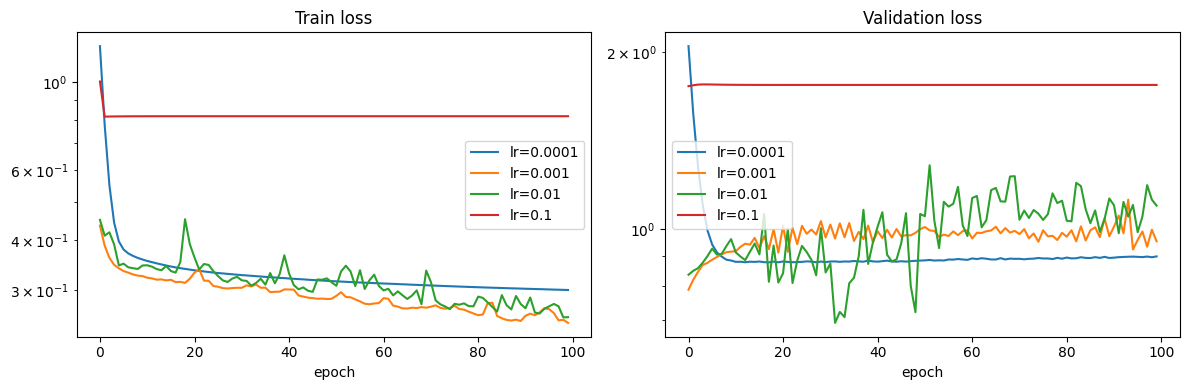

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

TARGET = None
if TARGET is None:
    kandidat = [c for c in df.columns if any(k in c.lower() for k in ['price', 'harga'])]
    TARGET = kandidat[0]
print("Target:", TARGET)

# Bersihkan data: buang baris kosong, pakai kolom angka saja sebagai fitur
df_bersih = df.dropna()
y = df_bersih[[TARGET]]
X = df_bersih.drop(columns=[TARGET]).select_dtypes(include='number')
print("Fitur:", list(X.columns), X.shape)

# Normalisasi (scaler dipisah untuk X dan y)
scaler_X, scaler_y = StandardScaler(), StandardScaler()
X = scaler_X.fit_transform(X)
y = scaler_y.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Tugas 4: ubah learning rate dan bandingkan loss
learning_rates = [0.0001, 0.001, 0.01, 0.1]
histories, hasil = {}, []

for lr in learning_rates:
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(X_train.shape[1],)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1)
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    h = model.fit(X_train, y_train, validation_data=(X_test, y_test),
                  epochs=100, batch_size=32, verbose=0)

    # RMSE dikembalikan ke satuan harga asli (rupiah)
    pred = scaler_y.inverse_transform(model.predict(X_test, verbose=0))
    asli = scaler_y.inverse_transform(y_test)
    rmse = float(np.sqrt(np.mean((pred - asli) ** 2)))

    histories[lr] = h.history
    hasil.append({
        'learning_rate': lr,
        'train_loss': h.history['loss'][-1],
        'val_loss': h.history['val_loss'][-1],
        'RMSE (rupiah)': rmse
    })

print(pd.DataFrame(hasil).to_string(index=False))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
for lr, hist in histories.items(): plt.plot(hist['loss'], label=f'lr={lr}')
plt.yscale('log'); plt.title('Train loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1, 2, 2)
for lr, hist in histories.items(): plt.plot(hist['val_loss'], label=f'lr={lr}')
plt.yscale('log'); plt.title('Validation loss'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()